# Lab 5: hydrogen and mystery gas spectra

Run all cells to reproduce the hydrogen analysis and report figures. `main.tex` preserves the original notes. The supplied handout is named LabON05-AtomicSpectra-v25.1.0.pdf and internally labels this material Lab 6. We use the user's Lab 5 numbering.

Experiment 3 is qualitative under the modified lab following flooding. No quantitative mystery gas fit or wavelength claim is made.

## Helium position statistics

For the four independent D3 placements, use the sample standard deviation for a new spectral line position and its standard error for the mean D3 position,

$$s_x=\sqrt{\frac{\sum_j(y_j-\bar y)^2}{N-1}}.$$

$$u_{\bar y}=\frac{s_x}{\sqrt{N}}.$$

Calculate the grating spacing from the known 587.6 nm line using the full geometry. Bench position uncertainties were not recorded, so the quoted result holds both bench separations fixed.

In [1]:
from pathlib import Path
import runpy
from IPython.display import display, Image
root=Path.cwd()
if not (root/'analyze_lab5.py').exists():
    root=root/'lab5'
results=runpy.run_path(str(root/'analyze_lab5.py'))['run_analysis']()
display(results['helium'])

{'D3_offsets_cm': [11.11, 11.18, 11.3, 11.3],
 'sample_count': 4,
 'mean_offset_cm': 11.2225,
 'sample_sd_cm': 0.09394147114028034,
 'mean_standard_error_cm': 0.04697073557014017,
 'distance_cm': 36.58,
 'reference_D3_nm': 587.6,
 'spacing_nm': 2003.4051171456226,
 'spacing_u_nm': 7.663739196893817,
 'other_lines_nm': [664.9085491900521,
  587.6,
  504.0848265979481,
  451.4199217655512],
 'other_lines_u_nm': [5.012084609674568,
  0.0,
  5.047083813757809,
  5.061816950620369]}

## Hydrogen wavelengths and uncertainty

The hydrogen separation is 27.85 cm, changed from the helium separation of 36.58 cm. Use

$$\lambda=\frac{dy}{\sqrt{L_H^2+y^2}}.$$

The SD of the D3 placements supplies the position uncertainty for all three hydrogen lines, including the violet line without a separately recorded uncertainty. The original 0.1 cm estimates for red and cyan are consistent with this empirical scale. Calculate the grating spacing and its uncertainty from the D3 mean, holding the reference wavelength and helium separation fixed,

$$d=\lambda_D\frac{\sqrt{L_{He}^2+\bar y_D^2}}{\bar y_D}.$$

$$u_d=\frac{\lambda_D L_{He}^2}{\bar y_D^2\sqrt{L_{He}^2+\bar y_D^2}}u_{\bar y}.$$

For a hydrogen line, let $a=\lambda/d$ and $g=dL_H^2/(L_H^2+y^2)^{3/2}$. The marginal wavelength variance is

$$u_\lambda^2=a^2u_d^2+g^2s_x^2.$$

Position scatter contributes about 6 nm per line, compared with about 2 nm from the common spacing error. The recorded line width is comparable to the position scatter, so we do not add it again as a separate independent error.

The predicted wavelengths use the handout's Rydberg constant in the Balmer formula before rounding. The largest individual deviation is the red line, at about 1.2 quoted uncertainties. These individual checks share the common grating error.

{'distance_cm': 27.85,
 'colors': ['Red', 'Cyan', 'Blue/violet'],
 'offsets_cm': [9.78, 6.97, 6.24],
 'offset_u_cm': 0.09394147114028034,
 'wavelength_nm': [663.7904944595255, 486.38968476738626, 438.0178427095479],
 'wavelength_u_nm': [6.218145671125499, 6.443619060769743, 6.498741138569928],
 'wavelength_covariance_nm2': [[38.665335587336784,
   4.724537074634439,
   4.254678094627668],
  [4.724537074634439, 41.52022660031515, 3.117597426455522],
  [4.254678094627668, 3.117597426455522, 42.23363638614116]],
 'initial_levels': [3.0, 4.0, 5.0],
 'reference_wavelength_nm': [656.1122763985122,
  486.00909362852764,
  433.93669073975684],
 'wavelength_difference_nm': [7.67821806101324,
  0.3805911388586196,
  4.081151969791051],
 'individual_reference_deviation': [1.2348083282557554,
  0.05906481051552959,
  0.6279911574827127],
 'spacing_error_component_nm': [2.539235418427467,
  1.8606140416709829,
  1.6755744913413992],
 'position_error_component_nm': [5.676056648514026,
  6.1691443481

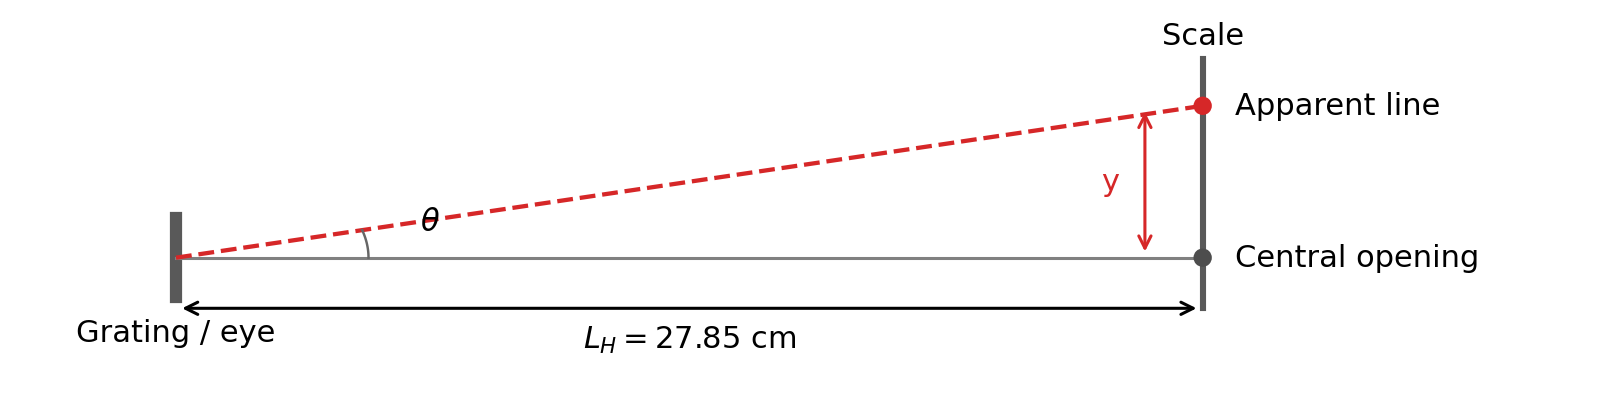

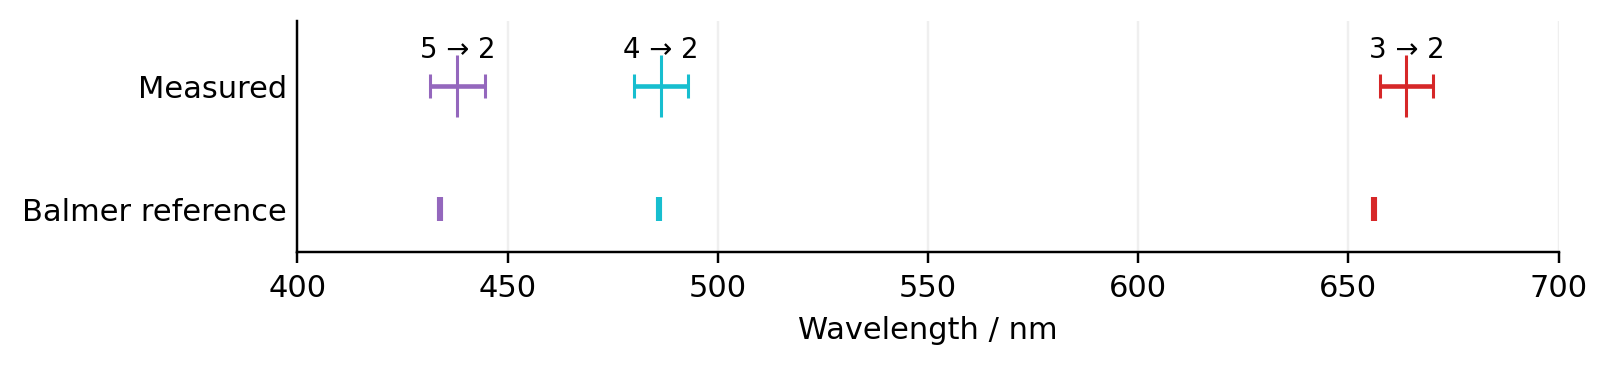

In [2]:
display(results['hydrogen'])
display(Image(filename=str(root/'figures/hydrogen_geometry.png')))
display(Image(filename=str(root/'figures/hydrogen_spectrum.png')))

## Bohr fit and agreement tests

Retain the common spacing uncertainty in the full wavelength covariance, then transform to reciprocal wavelengths. Fit

$$\frac{1}{\lambda}=m\frac{1}{n_i^2}+b.$$

Both parameters are free. Recover $R=-m$ and $n_f=\sqrt{-m/b}$, retaining the full slope and intercept covariance. In matrix notation, with vectors $a$ and $g$ from the wavelength derivatives,

$$C_\lambda=u_d^2aa^T+s_x^2\operatorname{diag}(g^2).$$

$$C_w=J C_\lambda J^T.$$

$$J=\operatorname{diag}(-\lambda^{-2}).$$

Here wavelengths are converted to meters before applying the derivative. With design matrix $X=[x,1]$, the parameter vector $\beta=(m,b)^T$ and its covariance are

$$C_\beta=(X^T C_w^{-1}X)^{-1}.$$

$$\beta=C_\beta X^T C_w^{-1}w.$$

The final-level gradient is

$$h=\left(-\frac{1}{2bn_f},\frac{m}{2b^2n_f}\right)^T.$$

$$u_{n_f}^2=h^T C_\beta h.$$

The raw residual statistic is $\chi^2=r^T C_w^{-1}r$. Three points and two fitted parameters leave one degree of freedom. The fit gives $\chi^2=0.2904$ and conditional $p=0.59$. A separate fixed Balmer comparison in wavelength space gives $\chi^2=1.7896$ for three degrees of freedom, with conditional $p=0.62$. The Rydberg and final-level estimates differ from their references by 0.23 and 0.47 quoted uncertainties.

These p values assume fixed Gaussian error scales. The reading scale is itself estimated from four placements, so the tests are approximate. Keep the input error scales fixed rather than reducing them because three points fit closely. The plotted residuals retain the original propagated errors, with discrete points and no connecting lines.

Unrecorded bench and alignment uncertainties remain possible systematic errors. A common wavelength scale changes $R$ but cancels in the slope-to-intercept ratio for $n_f$. Thus $n_f$ checks the spectral pattern without independently validating the absolute wavelength scale.

{'model': '1/lambda = slope/ni^2 + intercept, with both parameters free',
 'slope_per_m': -11068530.769076042,
 'intercept_per_m': 2737147.5997498464,
 'parameter_covariance': [[170107724933.80743, -16392157802.828796],
  [-16392157802.828796, 1739497282.6938767]],
 'R_per_m': 11068530.769076042,
 'R_u_per_m': 412441.1775439104,
 'final_level': 2.0109250296142207,
 'final_level_u': 0.02333343272587087,
 'chi_squared': 0.29042363325307624,
 'degrees_of_freedom': 1,
 'reduced_chi_squared': 0.29042363325307624,
 'conditional_p_value': 0.5899491839753859,
 'slope_u_per_m': 412441.1775439104,
 'intercept_u_per_m': 41707.28093143782,
 'raw_residual_per_m': [-811.4199543527793,
  10600.2274161987,
  -11394.348713681567],
 'input_uncertainties_rescaled': False}

{'reference_R_per_m': 10973731.568508,
 'R_deviation_in_u': 0.22984902024713558,
 'nf_deviation_in_u': 0.4682135604551495,
 'fixed_Balmer_chi_squared': 1.7896393013517473,
 'fixed_Balmer_degrees_of_freedom': 3,
 'fixed_Balmer_conditional_p_value': 0.6171921312747329,
 'p_value_assumption': 'Gaussian reading errors with estimated scales held fixed'}

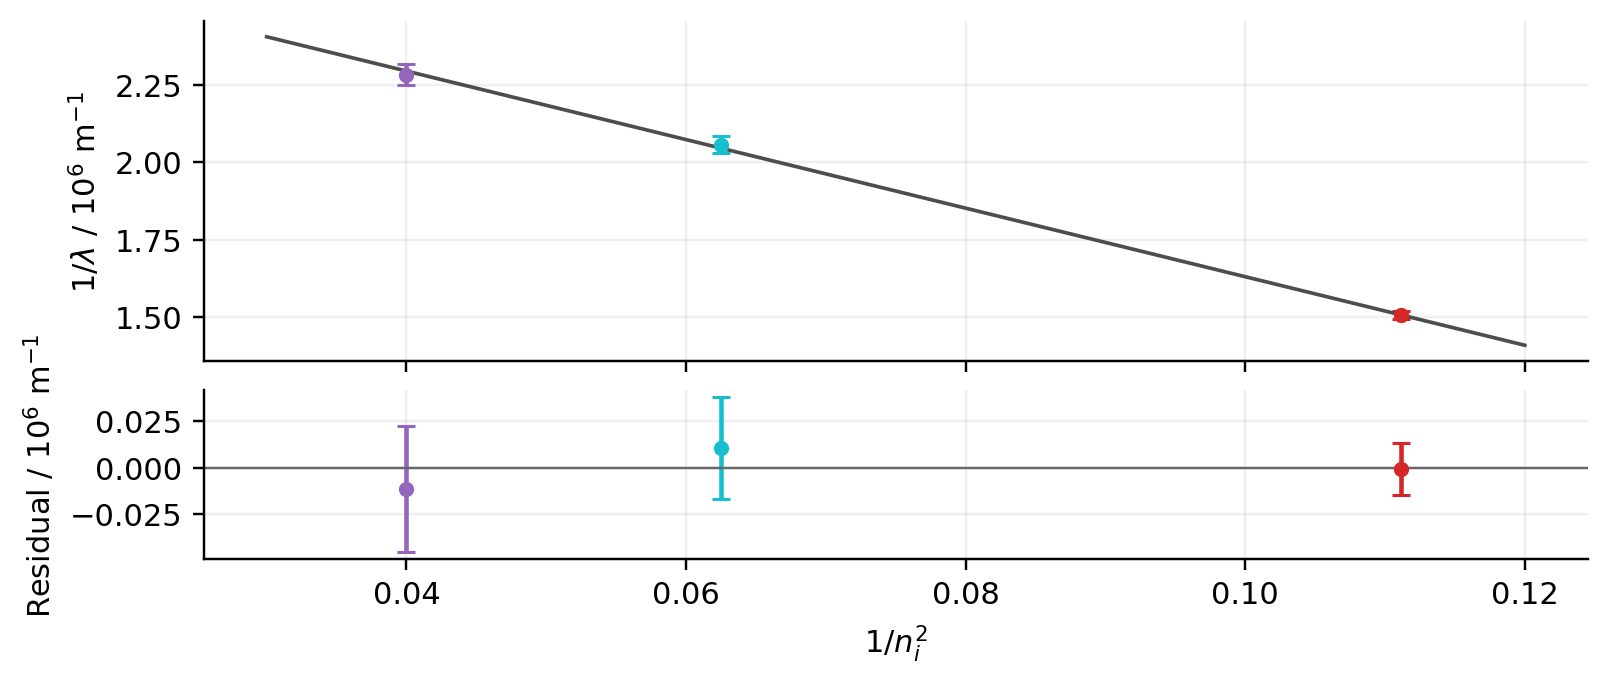

In [3]:
display(results['fit'])
display(results['agreement'])
display(Image(filename=str(root/'figures/hydrogen_fit.png')))

## Experiment 3: qualitative identifications

The recorded warm colored features in B favor neon. The many blue, green, and warm colored lines in C favor argon. These are qualitative matches within the handout's candidate set of nitrogen, neon, and argon.

Molecular nitrogen can also have a complex spectrum because rotational and vibrational transitions form bands. Without resolved band structure or measured wavelengths, C's identification is less secure. We do not invent missing line counts, absence of violet light, or statistical confidence.

The comparison uses the handout and the NIST strong line tables for neon and argon, linked in analysis_notes.md. No quantitative Experiment 3 analysis is performed.